# Analyze wearable data with pywearable

This tutorial follows one de-identified Oura participant from raw
loader access to domain features, sleep-anchored cycles,
hierarchies, trajectory post-processing, and visualization.

You will learn to:

- check which streams a loader exposes;
- extract activity, heart-rate, HRV, respiration, SpO2, sleep,
  provider-native, and adherence trajectories;
- distinguish calendar resolutions, sleep cycles, and hierarchical
  aggregation;
- impute selected gaps, add a historical trend, and choose a plot.

The saved outputs use measured values, while participant IDs and
calendar dates are replaced in tables and figures. To rerun the
notebook, set `PYWEARABLE_OURA_ROOT` to an Oura API v2 export root.

## Setup

The root directory contains one subdirectory per participant. This
local example selects the first directory beginning with `A_`; the
complete identifier is never displayed or stored in a title.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
from IPython.display import display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src" / "pywearable").is_dir():
    REPO_ROOT = next(
        parent
        for parent in Path.cwd().resolve().parents
        if (parent / "src" / "pywearable").is_dir()
    )
sys.path.insert(0, str(REPO_ROOT / "src"))

from pywearable import (
    activity,
    adherence,
    cycle,
    heart_rate,
    hrv,
    provider_features,
    respiration,
    schema,
    sleep,
    trajectory,
    visualization,
)
from pywearable.loader import OuraLoader

warnings.filterwarnings(
    "ignore",
    message=r".*Oura heart-rate samples have no unambiguous local offset.*",
)

data_root = Path(
    os.environ.get(
        "PYWEARABLE_OURA_ROOT",
        REPO_ROOT / "data_wearable" / "oura_20240822",
    )
)
if not data_root.is_dir():
    raise FileNotFoundError(
        "Set PYWEARABLE_OURA_ROOT to an Oura API v2 export root."
    )

loader = OuraLoader(data_root)
source_user = next(user for user in loader.get_user_ids() if user.startswith("A_"))
public_user = "example-participant"
print("Loaded one Oura participant")

Loaded one Oura participant


## Start with loader capabilities

“What can I extract?” always depends on the selected loader. Oura
supplies daily activity summaries, subdaily heart rate,
provider-computed HRV, nightly respiratory-rate and SpO2 summaries,
sleep summaries and stages, and readiness features. It does not
provide timestamped step intervals, so peak-hour activity and the
multi-stream weekly overview are not available from this loader.

In [2]:
capability_table = pd.DataFrame(
    {
        "loader setting": [
            "activity_source",
            "activity_primary_resolution",
            "hrv_source",
            "respiratory_rate_source",
            "spo2_source",
            "provider_features",
        ],
        "value": [
            loader.activity_source,
            loader.activity_primary_resolution,
            loader.hrv_source,
            loader.respiratory_rate_source,
            loader.spo2_source,
            f"{len(loader.provider_features)} Oura readiness features",
        ],
    }
)
display(capability_table)

,loader setting,value
0,activity_source,daily_summary
1,activity_primary_resolution,daily
2,hrv_source,provider_samples
3,respiratory_rate_source,provider_summary
4,spo2_source,provider_summary
5,provider_features,11 Oura readiness features


## Choose one well-supported example interval

The code below finds the 70-day activity interval with the most
observed days. This keeps the tutorial reproducible without
publishing the source calendar dates.

In [3]:
raw_activity = loader.load_activity_summary(source_user)
source_start = raw_activity[schema.CALENDAR_DATE_COL].min().normalize()
source_end = raw_activity[schema.CALENDAR_DATE_COL].max().normalize() + pd.Timedelta(days=1)

all_steps = activity.get_activity_statistics(
    loader,
    statistic=activity.ACTIVITY_STATISTIC_STEPS,
    user_id=source_user,
    start_date=source_start,
    end_date=source_end,
    resolution="daily",
)
step_series = all_steps.xs(source_user, level=schema.USER_COL)[
    activity.ACTIVITY_STATISTIC_STEPS
]
rolling_support = step_series.notna().rolling(70, min_periods=70).sum()
final_day = rolling_support.idxmax()
analysis_start = final_day - pd.Timedelta(days=69)
analysis_end = final_day + pd.Timedelta(days=1)
step_times = all_steps.index.get_level_values(schema.CALENDAR_DATE_COL)
steps = all_steps[(step_times >= analysis_start) & (step_times < analysis_end)]

PUBLIC_MONDAY = pd.Timestamp("2026-01-05")

def public_trajectory(frame):
    # Replace identifiers and shift datetimes while retaining values.
    rows = frame.reset_index()
    rows[schema.USER_COL] = public_user
    datetime_columns = [
        column
        for column in rows
        if pd.api.types.is_datetime64_any_dtype(rows[column])
    ]
    if datetime_columns:
        origin = min(rows[column].dropna().min() for column in datetime_columns)
        anchor = PUBLIC_MONDAY + pd.Timedelta(days=origin.weekday())
        for column in datetime_columns:
            rows[column] = anchor + (rows[column] - origin)
    return rows

print(f"Selected {len(steps)} study days; {step_series.loc[analysis_start:final_day].notna().sum()} contain steps")
display(public_trajectory(steps).head())

Selected 70 study days; 68 contain steps


,user_id,calendar_date,activity_steps,activity_steps__coverage
0,example-participant,2026-01-10,3806.0,1.0
1,example-participant,2026-01-11,26829.0,1.0
2,example-participant,2026-01-12,16185.0,1.0
3,example-participant,2026-01-13,10359.0,1.0
4,example-participant,2026-01-14,6286.0,1.0


## Extract features from every supported domain

Each domain returns the same trajectory shape: a `(user_id, time)`
index, feature columns, and matching coverage columns. The feature
names describe the measurement; the loader determines whether the
required stream exists.

In [4]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    hourly_hr = heart_rate.get_heart_rate_statistics(
        loader,
        statistic=heart_rate.HEART_RATE_STATISTIC_MEAN,
        user_id=source_user,
        start_date=analysis_start,
        end_date=analysis_end,
        resolution="1h",
        time_reference="local",
    )
    daily_hr = heart_rate.get_heart_rate_statistics(
        loader,
        statistic=[
            heart_rate.HEART_RATE_STATISTIC_MEAN,
            heart_rate.HEART_RATE_STATISTIC_REST,
        ],
        user_id=source_user,
        start_date=analysis_start,
        end_date=analysis_end,
        resolution="daily",
    )

nightly_sleep = sleep.get_sleep_statistics(
    loader,
    statistic=[
        sleep.SLEEP_STATISTIC_TST,
        sleep.SLEEP_STATISTIC_WASO,
        sleep.SLEEP_STATISTIC_BEDTIME,
        sleep.SLEEP_STATISTIC_SLEEP_SCORE,
        sleep.SLEEP_STATISTIC_CPD_MIDPOINT,
        sleep.SLEEP_STATISTIC_CPD_DURATION,
    ],
    user_id=source_user,
    start_date=analysis_start,
    end_date=analysis_end,
    resolution="nightly",
)
nightly_hrv = hrv.get_hrv_statistics(
    loader,
    statistic=hrv.HRV_STATISTIC_ROOT_MEAN_SQUARED_SUCCESSIVE_DIFFERENCES,
    user_id=source_user,
    start_date=analysis_start,
    end_date=analysis_end,
    resolution="nightly",
)
breathing = respiration.get_respiration_statistics(
    loader,
    statistic=[
        respiration.RESPIRATORY_RATE_STATISTIC_MEAN,
        respiration.SPO2_STATISTIC_MEAN,
    ],
    user_id=source_user,
    start_date=source_start,
    end_date=source_end,
    resolution="nightly",
)
readiness = provider_features.get_provider_features(
    loader,
    feature=provider_features.OURA_READINESS_SCORE,
    user_id=source_user,
    start_date=analysis_start,
    end_date=analysis_end,
)
availability = adherence.get_adherence(
    loader,
    metric=[adherence.ADHERENCE_HEART_RATE, adherence.ADHERENCE_SLEEP],
    user_id=source_user,
    start_date=analysis_start,
    end_date=analysis_start + pd.Timedelta(days=7),
    resolution="daily",
    time_reference="local",
)

trajectories = {
    "Activity": steps,
    "Heart rate": daily_hr,
    "HRV": nightly_hrv,
    "Respiration and SpO2": breathing,
    "Sleep": nightly_sleep,
    "Oura readiness": readiness,
    "Adherence": availability,
}
summary = pd.DataFrame(
    {
        "rows": {name: len(frame) for name, frame in trajectories.items()},
        "feature columns": {
            name: sum(
                not column.endswith("__coverage")
                and column not in {"period_start", "period_end"}
                for column in frame.columns
            )
            for name, frame in trajectories.items()
        },
        "non-missing values": {
            name: int(frame.notna().sum().sum())
            for name, frame in trajectories.items()
        },
    }
)
display(summary)

,rows,feature columns,non-missing values
Activity,70,1,138
Heart rate,70,2,66
HRV,70,7,960
Respiration and SpO2,202,2,232
Sleep,70,6,766
Oura readiness,70,1,130
Adherence,7,2,14


## Sleep-anchored cycles

A night runs from one main-sleep bedtime to its end, an awake cycle
runs from that end to the following bedtime, and a physiological
cycle runs from one bedtime to the next. The table reports elapsed
duration only, keeping the source dates private.

In [5]:
cycle_rows = []
for cycle_type in (
    cycle.CYCLE_NIGHT,
    cycle.CYCLE_AWAKE,
    cycle.CYCLE_PHYSIOLOGICAL,
):
    intervals = cycle.get_intervals(
        loader,
        cycle_type,
        user_id=source_user,
        start_date=analysis_start,
        end_date=analysis_end,
    ).xs(source_user, level=schema.USER_COL)
    valid = intervals[intervals["interval_valid"]].head(5)
    cycle_rows.append(
        pd.DataFrame(
            {
                "cycle": cycle_type,
                "study row": range(1, len(valid) + 1),
                "duration (hours)": (
                    valid["end_time"] - valid["start_time"]
                ).dt.total_seconds().div(3600).round(2).to_numpy(),
            }
        )
    )
display(pd.concat(cycle_rows, ignore_index=True))

,cycle,study row,duration (hours)
0,cycle_night,1,8.45
1,cycle_night,2,7.43
2,cycle_night,3,7.25
3,cycle_night,4,7.44
4,cycle_night,5,7.47
5,cycle_awake,1,15.77
6,cycle_awake,2,17.20
7,cycle_awake,3,15.98
8,cycle_awake,4,16.98
9,cycle_awake,5,17.38


## Hierarchies preserve the aggregation path

Here nightly total sleep time is the child level. Weekly means and
standard deviations are calculated from valid nights, so each
night receives equal weight. The lower-level observations and
parent estimates remain visible together.

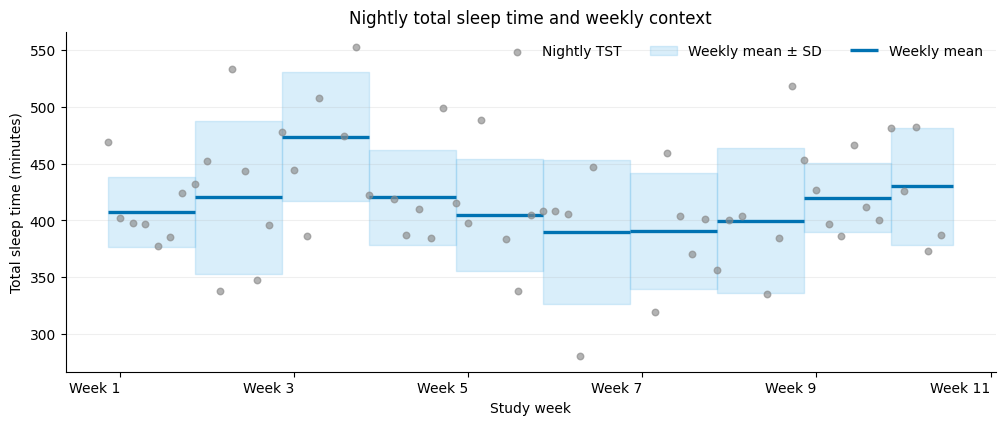

In [6]:
hierarchy_ax = visualization.plot_hierarchical_trajectory(
    loader,
    sleep.SLEEP_STATISTIC_TST,
    ("nightly", "weekly"),
    user_id=source_user,
    start_date=analysis_start,
    end_date=analysis_end,
    child_label="Nightly TST",
    center_label="Weekly mean",
    range_label="Weekly mean ± SD",
    title="Nightly total sleep time and weekly context",
    ylabel="Total sleep time (minutes)",
    show=False,
)

def relative_week(value, _):
    timestamp = pd.Timestamp(mdates.num2date(value)).tz_localize(None)
    return f"Week {(timestamp.normalize() - analysis_start).days // 7 + 1}"

hierarchy_ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
hierarchy_ax.xaxis.set_major_formatter(FuncFormatter(relative_week))
hierarchy_ax.tick_params(axis="x", rotation=0)
hierarchy_ax.set_xlabel("Study week")
plt.show()

## Imputation and trends are explicit trajectory operations

Imputation fills eligible gaps and adds `__is_imputed`. Trend
estimation then adds participant-specific baseline, normal-range,
deviation, and support columns. Coverage continues to describe the
source evidence.

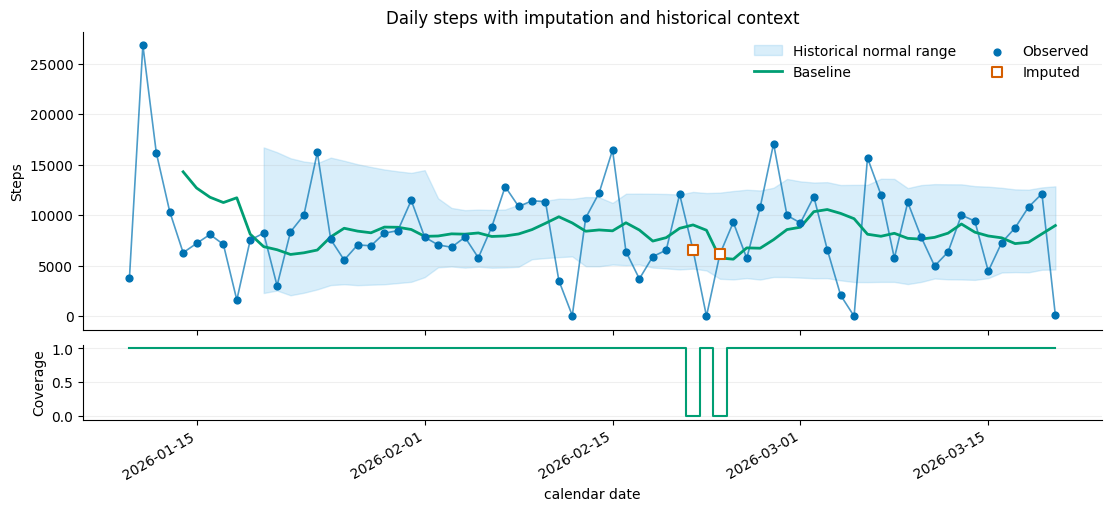

In [7]:
public_steps = public_trajectory(steps).set_index(steps.index.names)[steps.columns]
filled_steps = trajectory.impute_trajectory(
    public_steps,
    activity.ACTIVITY_STATISTIC_STEPS,
    method="rolling_median",
    window=7,
    min_periods=4,
)
trended_steps = trajectory.compute_trajectory_trend(
    filled_steps,
    activity.ACTIVITY_STATISTIC_STEPS,
    baseline_window=7,
    min_periods_baseline=4,
    normal_range_window=21,
    min_periods_normal_range=10,
)
trend_axes = visualization.plot_trajectory_trend(
    trended_steps,
    activity.ACTIVITY_STATISTIC_STEPS,
    show_coverage=True,
    title="Daily steps with imputation and historical context",
    ylabel="Steps",
    show=False,
)
plt.show()

## Calendar and within-day views

Calendar heatmaps suit daily outcomes. Coverage heatmaps and weekly
profiles require a subdaily trajectory; here they use hourly heart
rate. The profile summarizes repeated weekdays and is not a weekly
chronological aggregation.

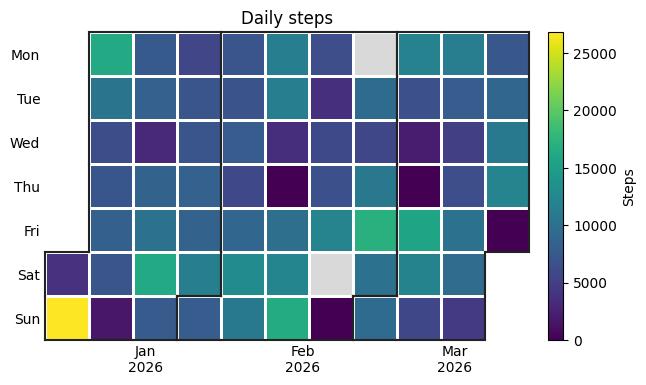

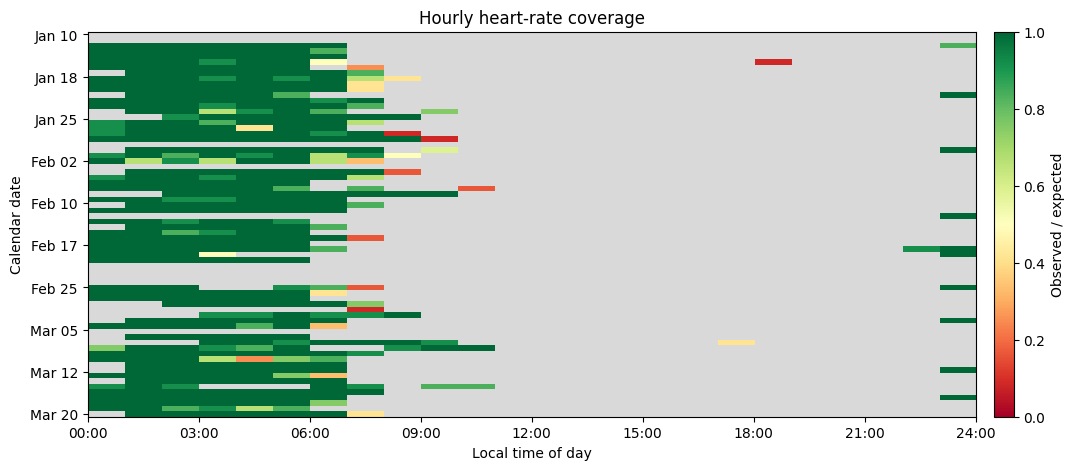

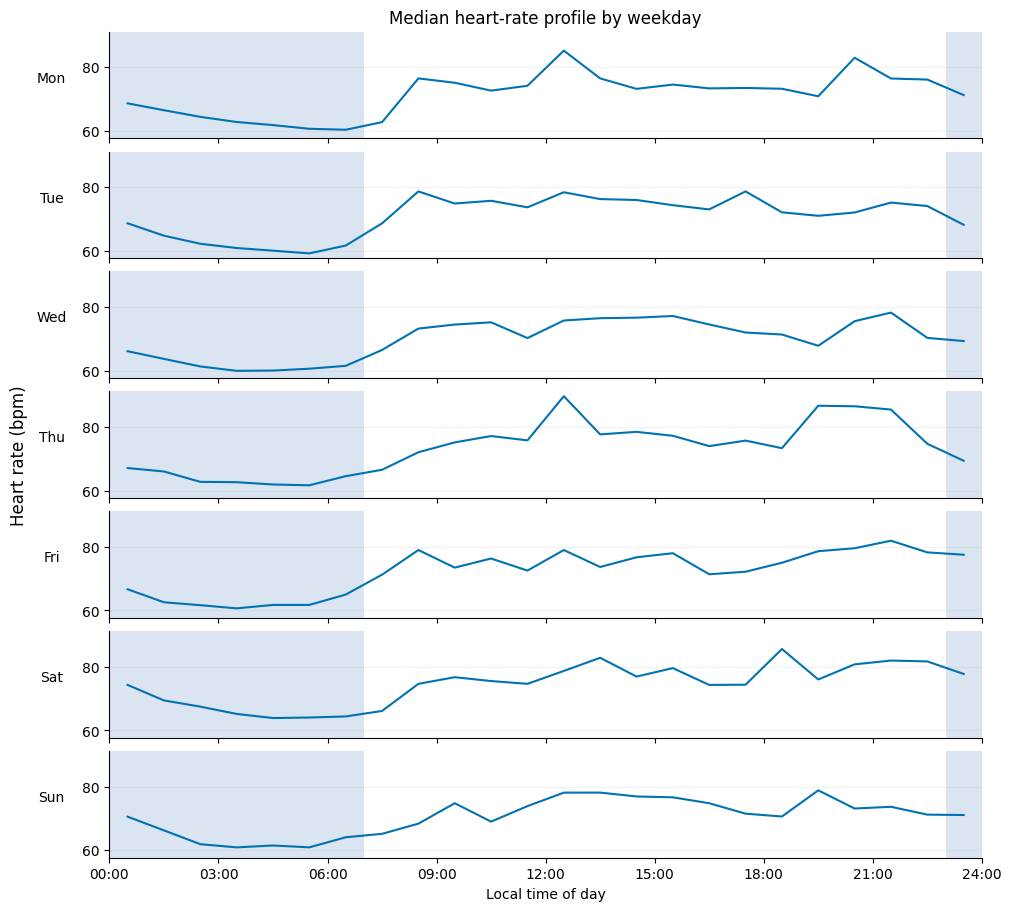

In [8]:
visualization.plot_calendar_heatmap(
    public_steps,
    activity.ACTIVITY_STATISTIC_STEPS,
    title="Daily steps",
    colorbar_label="Steps",
    show=False,
)
plt.show()

public_hourly = public_trajectory(hourly_hr).set_index(hourly_hr.index.names)[hourly_hr.columns]
visualization.plot_coverage_heatmap(
    public_hourly,
    heart_rate.HEART_RATE_STATISTIC_MEAN,
    title="Hourly heart-rate coverage",
    show=False,
)
plt.show()

visualization.plot_weekly_profile(
    public_hourly,
    heart_rate.HEART_RATE_STATISTIC_MEAN,
    aggregation="median",
    night_window=(23, 7),
    title="Median heart-rate profile by weekday",
    ylabel="Heart rate (bpm)",
    show=False,
)
plt.show()

## Loader-aware sleep views

Composite plots accept a loader because they coordinate sleep
summaries, stages, and heart-rate samples. `plot_sleep_summary`
takes inclusive sleep-calendar bounds, so the first selected night
retains stages from the preceding civil date.

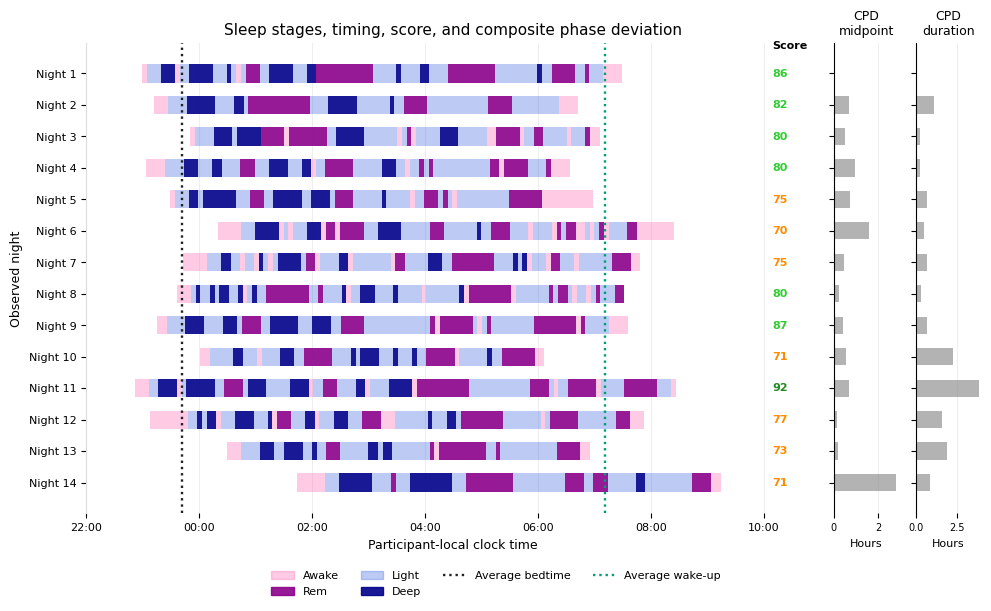

In [9]:
sleep_dates = loader.load_sleep_summary(
    source_user, analysis_start, analysis_end
)[schema.CALENDAR_DATE_COL]
summary_start = sleep_dates.iloc[0]
summary_end = sleep_dates.iloc[min(13, len(sleep_dates) - 1)]
sleep_axes = visualization.plot_sleep_summary(
    loader,
    source_user,
    summary_start,
    summary_end,
    cpd=("midpoint", "duration"),
    title="Sleep stages, timing, score, and composite phase deviation",
    fontsize=9,
    show=False,
)
sleep_axis = sleep_axes["sleep"]
sleep_axis.set_yticklabels(
    [f"Night {index + 1}" for index in range(len(sleep_axis.get_yticks()))]
)
sleep_axis.set_ylabel("Observed night")
plt.show()

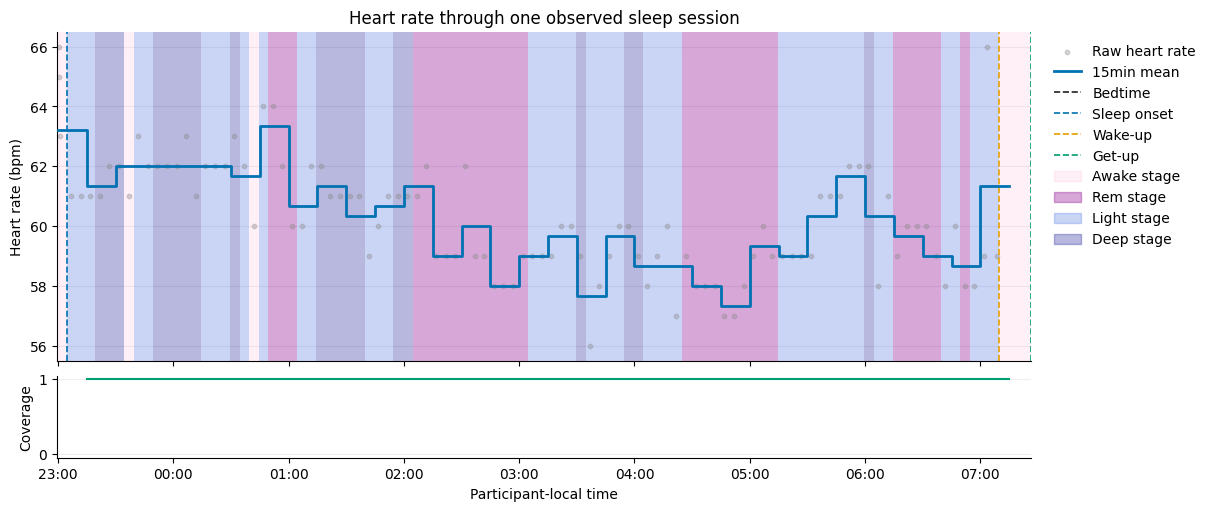

In [10]:
heart_rate_night = None
for row in loader.load_sleep_summary(source_user, analysis_start, analysis_end).itertuples(index=False):
    samples = loader.load_heart_rate(
        source_user,
        start_date=row.local_time,
        end_date=row.local_end_time,
        time_col=schema.LOCAL_TIME_COL,
    )
    if samples[schema.HEART_RATE_COL].notna().any():
        heart_rate_night = row.calendar_date
        break
assert heart_rate_night is not None
visualization.plot_sleep_heart_rate(
    loader,
    source_user,
    heart_rate_night,
    show_coverage=True,
    title="Heart rate through one observed sleep session",
    show=False,
)
plt.show()

## Period comparison and adherence monitoring

Period comparison expects an already aggregated trajectory. The
adherence summary aligns participants to their first evidence and
can use a fixed follow-up length. The Oura loader cannot produce
`plot_weekly_overview` because that plot requires timestamped step
intervals, whereas Oura supplies daily step totals.

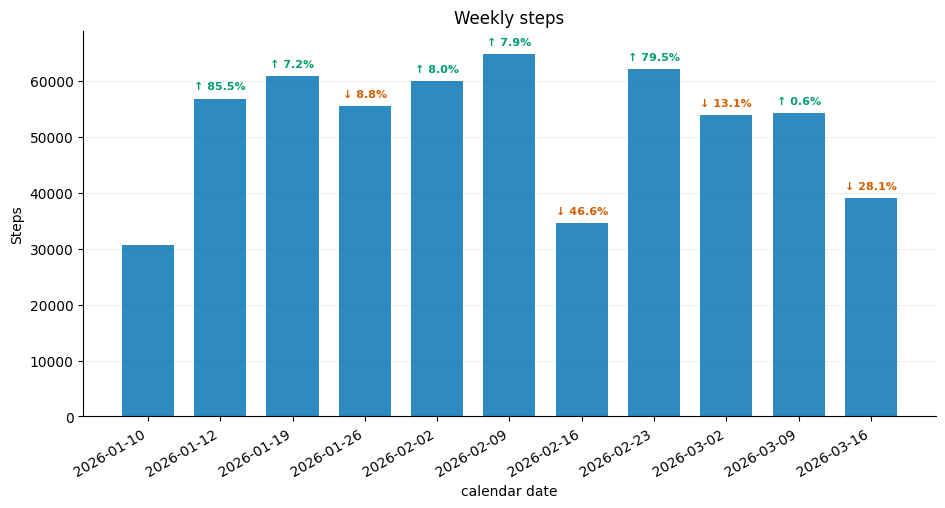

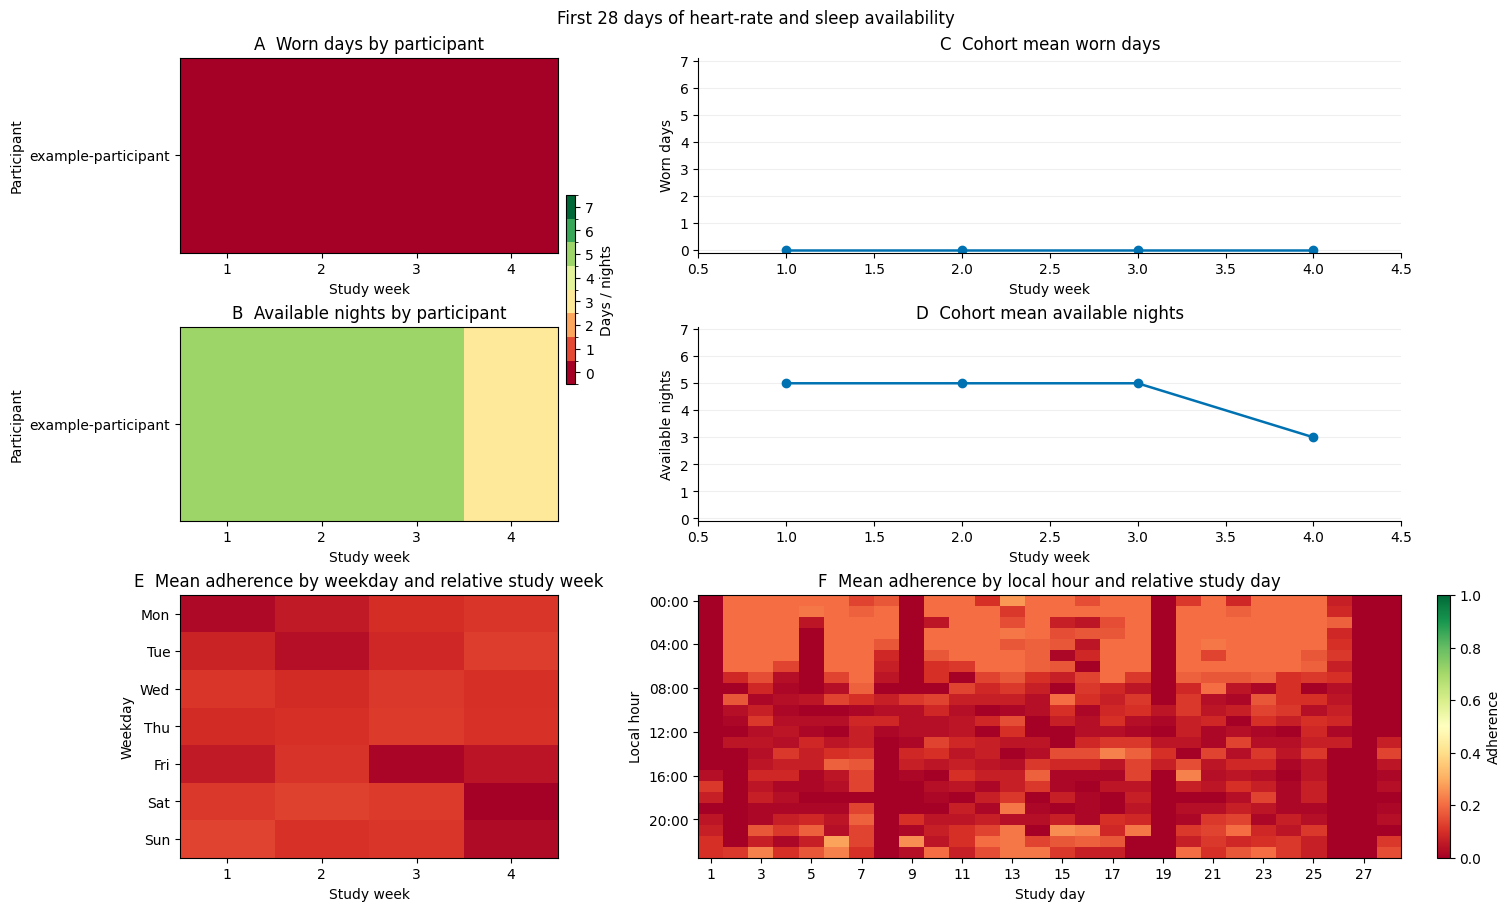

In [11]:
weekly_steps = activity.get_activity_statistics(
    loader,
    statistic=activity.ACTIVITY_STATISTIC_STEPS,
    user_id=source_user,
    start_date=analysis_start,
    end_date=analysis_end,
    resolution=("daily", "weekly"),
    aggregation="sum",
)
public_weekly = public_trajectory(weekly_steps).set_index(weekly_steps.index.names)[weekly_steps.columns]
weekly_feature = next(
    column
    for column in public_weekly
    if column.endswith("__weekly_sum")
)
visualization.plot_period_comparison(
    public_weekly,
    weekly_feature,
    title="Weekly steps",
    ylabel="Steps",
    show=False,
)
plt.show()

adherence_axes = visualization.plot_adherence_summary(
    loader,
    metric=adherence.ADHERENCE_HEART_RATE,
    user_id=source_user,
    follow_up_days=28,
    include_without_evidence=False,
    title="First 28 days of heart-rate and sleep availability",
    show=False,
)
for panel in ("wearing_days", "available_nights"):
    adherence_axes[panel].set_yticklabels([public_user])
plt.show()

## Exercise

Choose one feature above and answer the same question at two
resolutions. For example, compare direct daily heart-rate means
with a weekly hierarchy built from qualified daily means.

1. Decide the primary and parent resolutions.
2. Set a coverage threshold appropriate for the primary rows.
3. Plot child observations against the parent estimate.
4. Explain what would change if raw samples were pooled directly.

In [12]:
# Your analysis here.
# daily = heart_rate.get_heart_rate_statistics(...)
# weekly = heart_rate.get_heart_rate_statistics(
#     ..., resolution=("daily", "weekly"), aggregation="mean"
# )

## Practical checks

- Confirm that the loader exposes the stream required by a feature.
- Treat `end_date` as exclusive for feature extraction; the sleep
  summary visualization documents its inclusive calendar bounds.
- Inspect coverage before setting thresholds.
- Use a hierarchy when child windows should receive equal weight.
- Keep imputation and trend settings in the analysis record.
- Retain provider names for provider-defined outcomes such as Oura
  readiness.